# Reinforcement Learning - Assignment 2

## Policy Iteration and Custom Gymnasium Environment (`GridMazeEnv`)


In [7]:
import os
import time
import numpy as np
import pygame
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from gymnasium.wrappers import RecordVideo

## 1. Custom GridMaze Environment with Model Dynamics

- **Grid Dimension**: $5 \times 5$
- **Observation Space**: 8 discrete integers `[agent_x, agent_y, goal_x, goal_y, bad1_x, bad1_y, bad2_x, bad2_y]`
- **Action Space**: 4 discrete deterministic actions (`0`: Right, `1`: Up, `2`: Left, `3`: Down)
- **Rewards**: $+1$ at Goal (`G`), $-1$ at Bad cells (`X`), $0$ otherwise
- **Render Modes**: `"human"` (Pygame window), `"rgb_array"` (off-screen Pygame surface for `RecordVideo`), and `"ansi"` (text grid)


In [8]:
class GridMazeEnv(gym.Env):
    metadata = {"render_modes": ["human", "rgb_array", "ansi"], "render_fps": 4}

    def __init__(self, render_mode=None, grid_size=5):
        super().__init__()
        self.grid_size = grid_size
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(
            low=0, high=self.grid_size - 1, shape=(8,), dtype=np.int32
        )
        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode
        self.window_size = 400
        self.window = None
        self.clock = None

        self.agent_pos = None
        self.goal_pos = None
        self.bad1_pos = None
        self.bad2_pos = None
        self.extra_goals = []  # Optional list of additional goal positions for Question 4
        self.steps_count = 0
        self.max_steps = 100

    def _get_obs(self):
        return np.array(
            [
                self.agent_pos[0],
                self.agent_pos[1],
                self.goal_pos[0],
                self.goal_pos[1],
                self.bad1_pos[0],
                self.bad1_pos[1],
                self.bad2_pos[0],
                self.bad2_pos[1],
            ],
            dtype=np.int32,
        )

    def is_terminal(self, state):
        """Returns True if state (x, y) is a Goal or Bad cell."""
        if np.array_equal(state, self.goal_pos):
            return True
        for g in self.extra_goals:
            if np.array_equal(state, g):
                return True
        if np.array_equal(state, self.bad1_pos) or np.array_equal(state, self.bad2_pos):
            return True
        return False

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        all_positions = [
            (x, y) for x in range(self.grid_size) for y in range(self.grid_size)
        ]
        chosen_indices = self.np_random.choice(
            len(all_positions), size=4, replace=False
        )
        positions = [all_positions[idx] for idx in chosen_indices]
        self.agent_pos = np.array(positions[0], dtype=np.int32)
        self.goal_pos = np.array(positions[1], dtype=np.int32)
        self.bad1_pos = np.array(positions[2], dtype=np.int32)
        self.bad2_pos = np.array(positions[3], dtype=np.int32)
        self.extra_goals = []
        self.steps_count = 0

        observation = self._get_obs()
        if self.render_mode == "human":
            self._render_frame()

        return observation, {}

    def step(self, action):
        self.steps_count += 1
        next_pos, reward, terminated = self.get_transition_model(
            tuple(self.agent_pos), int(action)
        )
        self.agent_pos = np.array(next_pos, dtype=np.int32)

        truncated = bool(self.steps_count >= self.max_steps and not terminated)

        if self.render_mode == "human":
            self._render_frame()

        return self._get_obs(), float(reward), bool(terminated), truncated, {}

    def get_transition_model(self, state, action):
        """
        Encapsulates deterministic environment dynamics (transitions and rewards) for planning.
        State: (x, y)
        Action: 0: Right, 1: Up, 2: Left, 3: Down
        Returns: (next_state, reward, terminated)
        """
        if self.is_terminal(state):
            return state, 0.0, True

        x, y = state
        dx, dy = 0, 0
        if action == 0:  # Right
            dx = 1
        elif action == 1:  # Up
            dy = -1
        elif action == 2:  # Left
            dx = -1
        elif action == 3:  # Down
            dy = 1

        nx = int(np.clip(x + dx, 0, self.grid_size - 1))
        ny = int(np.clip(y + dy, 0, self.grid_size - 1))
        next_pos = (nx, ny)

        # Check terminal / reward conditions
        if np.array_equal(next_pos, self.goal_pos) or any(
            np.array_equal(next_pos, g) for g in self.extra_goals
        ):
            return next_pos, 1.0, True
        elif np.array_equal(next_pos, self.bad1_pos) or np.array_equal(
            next_pos, self.bad2_pos
        ):
            return next_pos, -1.0, True
        else:
            return next_pos, 0.0, False

    def render(self):
        if self.render_mode == "ansi":
            grid = [["." for _ in range(self.grid_size)] for _ in range(self.grid_size)]
            gx, gy = self.goal_pos
            grid[gy][gx] = "G"
            for egx, egy in self.extra_goals:
                grid[egy][egx] = "G"
            b1x, b1y = self.bad1_pos
            grid[b1y][b1x] = "X"
            b2x, b2y = self.bad2_pos
            grid[b2y][b2x] = "X"
            ax, ay = self.agent_pos
            grid[ay][ax] = "S"
            output = "\n".join([" ".join(row) for row in grid])
            print(output)
            return output
        elif self.render_mode in ("human", "rgb_array"):
            return self._render_frame()

    def _render_frame(self):
        if self.window is None and self.render_mode == "human":
            pygame.init()
            pygame.display.init()
            self.window = pygame.display.set_mode((self.window_size, self.window_size))
            pygame.display.set_caption("GridMaze - Policy Iteration")
        if self.clock is None and self.render_mode == "human":
            self.clock = pygame.time.Clock()

        canvas = pygame.Surface((self.window_size, self.window_size))
        canvas.fill((255, 255, 255))
        cell_size = self.window_size / self.grid_size

        # Draw Goal cells (Green)
        for g_pos in [self.goal_pos] + list(self.extra_goals):
            pygame.draw.rect(
                canvas,
                (40, 180, 99),
                pygame.Rect(
                    g_pos[0] * cell_size,
                    g_pos[1] * cell_size,
                    cell_size,
                    cell_size,
                ),
            )

        # Draw Bad cells (Red)
        for b_pos in [self.bad1_pos, self.bad2_pos]:
            pygame.draw.rect(
                canvas,
                (231, 76, 60),
                pygame.Rect(
                    b_pos[0] * cell_size, b_pos[1] * cell_size, cell_size, cell_size
                ),
            )

        # Draw Agent (Blue circle)
        agent_center = (
            int((self.agent_pos[0] + 0.5) * cell_size),
            int((self.agent_pos[1] + 0.5) * cell_size),
        )
        pygame.draw.circle(canvas, (41, 128, 185), agent_center, int(cell_size / 3))

        # Draw Grid lines
        for x in range(self.grid_size + 1):
            pygame.draw.line(
                canvas,
                (180, 180, 180),
                (0, cell_size * x),
                (self.window_size, cell_size * x),
                width=2,
            )
            pygame.draw.line(
                canvas,
                (180, 180, 180),
                (cell_size * x, 0),
                (cell_size * x, self.window_size),
                width=2,
            )

        if self.render_mode == "human":
            self.window.blit(canvas, canvas.get_rect())
            pygame.event.pump()
            pygame.display.update()
            self.clock.tick(self.metadata["render_fps"])
        else:  # rgb_array
            return np.transpose(
                np.array(pygame.surfarray.pixels3d(canvas)), axes=(1, 0, 2)
            )

    def close(self):
        if self.window is not None:
            pygame.display.quit()
            pygame.quit()
            self.window = None
            self.clock = None

## 2. Policy Iteration Algorithm Implementation

We implement **Synchronous Policy Iteration** for the current episode's maze configuration:

1. **Initialization**: $V(s) = 0$ for all $s \in [0, 4]^2$, and uniform random policy $\pi(s, a) = 0.25$.
2. **Synchronous Policy Evaluation**: Maintain $V$ and $V_{\text{new}}$ across sweeps until $\max_s |V_{\text{new}}(s) - V(s)| < \theta$, ensuring terminal states have $0$ future value:
   $$V_{\text{new}}(s) = \sum_{a=0}^{3} \pi(s, a) \left[ r + \gamma (1 - \mathbb{I}_{\text{terminal}}(s')) V(s') \right]$$
3. **Policy Improvement**: Compute $Q(s, a)$ for all 4 actions and split probability uniformly across all tied optimal actions within floating-point tolerance $\epsilon = 10^{-8}$ (`np.isclose`).


In [9]:
def policy_evaluation(env, policy, V, gamma=0.9, theta=1e-6):
    """
    Synchronous Policy Evaluation (two-array approach).
    Returns updated value table V and number of evaluation sweeps.
    """
    grid_size = env.grid_size
    n_actions = env.action_space.n
    sweeps = 0

    while True:
        delta = 0.0
        V_new = np.zeros_like(V)
        sweeps += 1

        for x in range(grid_size):
            for y in range(grid_size):
                state = (x, y)
                if env.is_terminal(state):
                    V_new[x, y] = 0.0
                    continue

                v = 0.0
                for a in range(n_actions):
                    action_prob = policy[x, y, a]
                    if action_prob > 0:
                        next_state, reward, terminated = env.get_transition_model(
                            state, a
                        )
                        nx, ny = next_state
                        next_val = 0.0 if terminated else V[nx, ny]
                        v += action_prob * (reward + gamma * next_val)

                V_new[x, y] = v
                delta = max(delta, abs(V_new[x, y] - V[x, y]))

        V = V_new
        if delta < theta:
            break

    return V, sweeps


def policy_improvement(env, policy, V, gamma=0.9, tie_tol=1e-8):
    """
    Policy Improvement with tolerance-based uniform tie-breaking.
    Returns (new_policy, policy_stable).
    """
    grid_size = env.grid_size
    n_actions = env.action_space.n
    new_policy = np.zeros_like(policy)

    for x in range(grid_size):
        for y in range(grid_size):
            state = (x, y)
            if env.is_terminal(state):
                new_policy[x, y] = np.ones(n_actions) / n_actions
                continue

            q_values = np.zeros(n_actions)
            for a in range(n_actions):
                next_state, reward, terminated = env.get_transition_model(state, a)
                nx, ny = next_state
                next_val = 0.0 if terminated else V[nx, ny]
                q_values[a] = reward + gamma * next_val

            q_max = np.max(q_values)
            best_actions = np.where(
                np.isclose(q_values, q_max, atol=tie_tol, rtol=0.0)
            )[0]
            new_policy[x, y, best_actions] = 1.0 / len(best_actions)

    policy_stable = np.allclose(policy, new_policy)
    return new_policy, policy_stable


def policy_iteration(env, gamma=0.9, theta=1e-6, tie_tol=1e-8):
    """
    Full Policy Iteration algorithm.
    Returns: (V, policy, num_outer_iterations, total_eval_sweeps)
    """
    grid_size = env.grid_size
    n_actions = env.action_space.n

    V = np.zeros((grid_size, grid_size), dtype=np.float64)
    policy = np.ones((grid_size, grid_size, n_actions), dtype=np.float64) / n_actions

    num_iterations = 0
    total_sweeps = 0

    while True:
        num_iterations += 1
        V, sweeps = policy_evaluation(env, policy, V, gamma=gamma, theta=theta)
        total_sweeps += sweeps
        policy, policy_stable = policy_improvement(
            env, policy, V, gamma=gamma, tie_tol=tie_tol
        )
        if policy_stable:
            break

    return V, policy, num_iterations, total_sweeps

## 3. Visualizing Value Function & Optimal Stochastic Policy

Let's test Policy Iteration on a single episode layout and visualize the learned state-value table $V^*(s)$ and optimal policy arrows $\pi^*(s, a)$.


Initial Maze Layout (ANSI):
. . S X .
G . . . .
. . . X .
. . . . .
. . . . .

Converged in 5 Policy Improvement iterations (199 total evaluation sweeps).


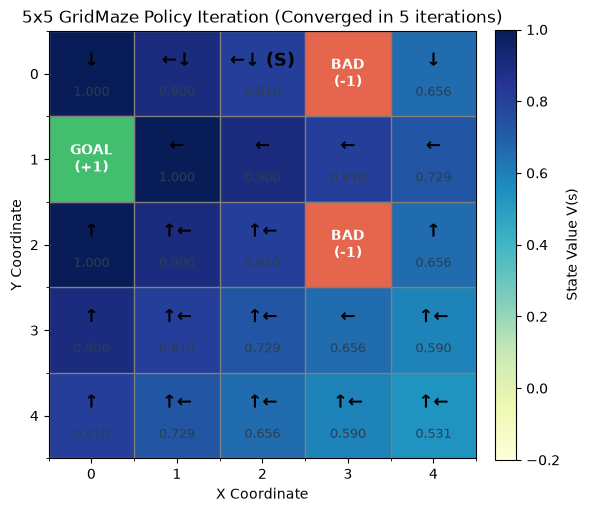

In [10]:
ACTION_ARROWS = {0: "→", 1: "↑", 2: "←", 3: "↓"}


def plot_value_and_policy(env, V, policy, title="Optimal Value Function & Policy"):
    grid_size = env.grid_size
    fig, ax = plt.subplots(figsize=(6, 6))

    # Transpose V so x is horizontal (columns) and y is vertical (rows)
    im = ax.imshow(V.T, cmap="YlGnBu", origin="upper", vmin=-0.2, vmax=1.0)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="State Value V(s)")

    for x in range(grid_size):
        for y in range(grid_size):
            state = (x, y)
            if np.array_equal(state, env.goal_pos) or any(
                np.array_equal(state, g) for g in env.extra_goals
            ):
                label = "GOAL\n(+1)"
                ax.add_patch(
                    plt.Rectangle((x - 0.5, y - 0.5), 1, 1, color="#28b463", alpha=0.85)
                )
                ax.text(
                    x,
                    y,
                    label,
                    ha="center",
                    va="center",
                    color="white",
                    fontweight="bold",
                    fontsize=10,
                )
            elif np.array_equal(state, env.bad1_pos) or np.array_equal(
                state, env.bad2_pos
            ):
                label = "BAD\n(-1)"
                ax.add_patch(
                    plt.Rectangle((x - 0.5, y - 0.5), 1, 1, color="#e74c3c", alpha=0.85)
                )
                ax.text(
                    x,
                    y,
                    label,
                    ha="center",
                    va="center",
                    color="white",
                    fontweight="bold",
                    fontsize=10,
                )
            else:
                best_acts = np.where(policy[x, y] > 0)[0]
                arrows = "".join(ACTION_ARROWS[a] for a in best_acts)
                start_tag = " (S)" if np.array_equal(state, env.agent_pos) else ""
                ax.text(
                    x,
                    y - 0.15,
                    f"{arrows}{start_tag}",
                    ha="center",
                    va="center",
                    color="black",
                    fontweight="bold",
                    fontsize=13,
                )
                ax.text(
                    x,
                    y + 0.22,
                    f"{V[x, y]:.3f}",
                    ha="center",
                    va="center",
                    color="#2c3e50",
                    fontsize=9,
                )

    ax.set_xticks(range(grid_size))
    ax.set_yticks(range(grid_size))
    ax.set_xticks(np.arange(-0.5, grid_size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, grid_size, 1), minor=True)
    ax.grid(which="minor", color="gray", linestyle="-", linewidth=1)
    ax.set_xlabel("X Coordinate")
    ax.set_ylabel("Y Coordinate")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


# Run on a sample episode
env = GridMazeEnv(render_mode="ansi")
obs, _ = env.reset(seed=42)
print("Initial Maze Layout (ANSI):")
env.render()

V, policy, iters, sweeps = policy_iteration(env, gamma=0.9, theta=1e-6)
print(
    f"\nConverged in {iters} Policy Improvement iterations ({sweeps} total evaluation sweeps)."
)
plot_value_and_policy(
    env,
    V,
    policy,
    title=f"5x5 GridMaze Policy Iteration (Converged in {iters} iterations)",
)

## 4. Episodic Re-planning Evaluation & Metrics Tracking

Because layouts are sampled uniformly at random without filtering unreachable configurations, we evaluate across **200 random episodes** and track:

- **Success Rate**: Agent reaches Goal `G` ($+1$)
- **Collision Rate**: Agent hits Bad cell `X` ($-1$)
- **Truncation Rate (Unsolvable Layouts)**: Start `S` or Goal `G` is completely walled off by `X1` and `X2` in a corner, so the optimal agent safely avoids $-1$ by bumping into the wall ($0$ reward) until `max_steps`.
- **Convergence Iterations**: Number of Policy Iteration steps per episode.


In [ ]:
def evaluate_policy_iteration(num_episodes=200, gamma=0.9, seed=100):
    eval_env = GridMazeEnv(render_mode=None)
    rng = np.random.default_rng(seed)

    successes = 0
    collisions = 0
    truncations = 0
    rewards_all = []
    steps_solvable = []
    pi_iterations = []
    eval_sweeps_list = []

    for ep in range(num_episodes):
        obs, _ = eval_env.reset(seed=seed + ep)
        V, policy, iters, sweeps = policy_iteration(eval_env, gamma=gamma)
        pi_iterations.append(iters)
        eval_sweeps_list.append(sweeps)

        terminated = False
        truncated = False
        ep_reward = 0.0
        steps = 0

        while not (terminated or truncated):
            ax, ay = eval_env.agent_pos
            action = rng.choice(eval_env.action_space.n, p=policy[ax, ay])
            obs, reward, terminated, truncated, _ = eval_env.step(action)
            ep_reward += reward
            steps += 1

        rewards_all.append(ep_reward)
        if terminated and ep_reward > 0:
            successes += 1
            steps_solvable.append(steps)
        elif terminated and ep_reward < 0:
            collisions += 1
        elif truncated:
            truncations += 1

    eval_env.close()

    print(f"=== Evaluation over {num_episodes} Random Episodes ===")
    print(
        f"Success Rate (Reached Goal):         {successes / num_episodes * 100:.2f}% ({successes}/{num_episodes})"
    )
    print(
        f"Collision Rate (Hit Bad Cell):       {collisions / num_episodes * 100:.2f}% ({collisions}/{num_episodes})"
    )
    print(
        f"Truncation Rate (Trapped Layouts):   {truncations / num_episodes * 100:.2f}% ({truncations}/{num_episodes})"
    )
    print(
        f"Success Rate on Solvable Layouts:    {successes / max(1, (num_episodes - truncations)) * 100:.2f}%"
    )
    print(
        f"Average Steps to Goal (Solvable):    {np.mean(steps_solvable):.2f} ± {np.std(steps_solvable):.2f}"
    )
    print(
        f"Policy Iteration Outer Iterations:   mean={np.mean(pi_iterations):.2f}, min={np.min(pi_iterations)}, max={np.max(pi_iterations)}"
    )
    print(
        f"Policy Evaluation Total Sweeps:      mean={np.mean(eval_sweeps_list):.2f}, min={np.min(eval_sweeps_list)}, max={np.max(eval_sweeps_list)}"
    )
    return pi_iterations, eval_sweeps_list


pi_iterations, eval_sweeps_list = evaluate_policy_iteration(num_episodes=200)

=== Evaluation over 200 Random Episodes ===
Success Rate (Reached Goal):         100.00% (200/200)
Collision Rate (Hit Bad Cell):       0.00% (0/200)
Truncation Rate (Trapped Layouts):   0.00% (0/200)
Success Rate on Solvable Layouts:    100.00%
Average Steps to Goal (Solvable):    3.38 ± 1.77
Policy Iteration Outer Iterations:   mean=4.42, min=3, max=6
Policy Evaluation Total Sweeps:      mean=152.56, min=53, max=252


## 5. Recording the Trained Agent with `RecordVideo` Wrapper

We use Gymnasium's `RecordVideo` wrapper with `render_mode="rgb_array"` to record episodes of the agent executing the optimal Policy Iteration policy.


In [ ]:
video_folder = "videos"
os.makedirs(video_folder, exist_ok=True)

base_env = GridMazeEnv(render_mode="rgb_array")
base_env.metadata["render_fps"] = 10  # 10 FPS video stream
video_env = RecordVideo(
    base_env,
    video_folder=video_folder,
    name_prefix="grid_maze_policy_iteration",
    episode_trigger=lambda ep_id: True,  # Record all episodes in this run
    fps=10,
)


def hold_current_frame(video_env, num_frames=8):
    """Duplicates the current frame in the video buffer so each move is clearly visible one by one."""
    if getattr(video_env, "recording", False):
        for _ in range(num_frames):
            video_env._capture_frame()


rng = np.random.default_rng(7)
num_recorded_episodes = 5

for ep in range(num_recorded_episodes):
    obs, _ = video_env.reset(seed=42 + ep)
    # Hold initial starting state for ~1 second (10 frames at 10 FPS)
    hold_current_frame(video_env, num_frames=9)

    # Re-plan on the underlying unwrapped environment for the current episode layout
    V, policy, iters, sweeps = policy_iteration(video_env.unwrapped, gamma=0.9)

    terminated = False
    truncated = False
    total_reward = 0.0
    steps = 0

    while not (terminated or truncated):
        ax, ay = video_env.unwrapped.agent_pos
        action = int(rng.choice(video_env.action_space.n, p=policy[ax, ay]))
        obs, reward, terminated, truncated, _ = video_env.step(action)
        # Hold each step for ~0.8 seconds (8 frames at 10 FPS) so moves appear one by one
        hold_current_frame(video_env, num_frames=7)
        total_reward += reward
        steps += 1

    # Hold final Goal state for an extra second before closing the episode video
    hold_current_frame(video_env, num_frames=10)

    print(
        f"Recorded Episode {ep + 1}: steps={steps}, reward={total_reward:.1f}, PI_iterations={iters}"
    )

video_env.close()
print(
    f"\nVideos saved to '{os.path.abspath(video_folder)}' directory: {os.listdir(video_folder)}"
)

Recorded Episode 1: steps=3, reward=1.0, PI_iterations=5
Recorded Episode 2: steps=4, reward=1.0, PI_iterations=5
Recorded Episode 3: steps=4, reward=1.0, PI_iterations=5
Recorded Episode 4: steps=5, reward=1.0, PI_iterations=4
Recorded Episode 5: steps=7, reward=1.0, PI_iterations=4

Videos saved to 'd:\college\RL\assignments\assignment 2\videos' directory: ['grid_maze_policy_iteration-episode-0.mp4', 'grid_maze_policy_iteration-episode-1.mp4', 'grid_maze_policy_iteration-episode-2.mp4', 'grid_maze_policy_iteration-episode-3.mp4', 'grid_maze_policy_iteration-episode-4.mp4']


## 6. Multiple Goal Cells Experiment (Question 4)

To demonstrate how Policy Iteration behaves when multiple goal cells exist in the maze, we configure a $5 \times 5$ layout with **two Goal cells**:

- $G_1$ at `(0, 0)` (Top-Left)
- $G_2$ at `(4, 4)` (Bottom-Right)
- Bad cells $X_1$ at `(2, 1)` and $X_2$ at `(1, 3)`
- Start $S$ at `(2, 2)` (Center)


Multi-Goal Maze Layout (ANSI):
G . . . G
. . X . .
. . S . .
. X . . .
G . . . G

Multi-Goal Policy Iteration converged in 3 iterations (42 evaluation sweeps).


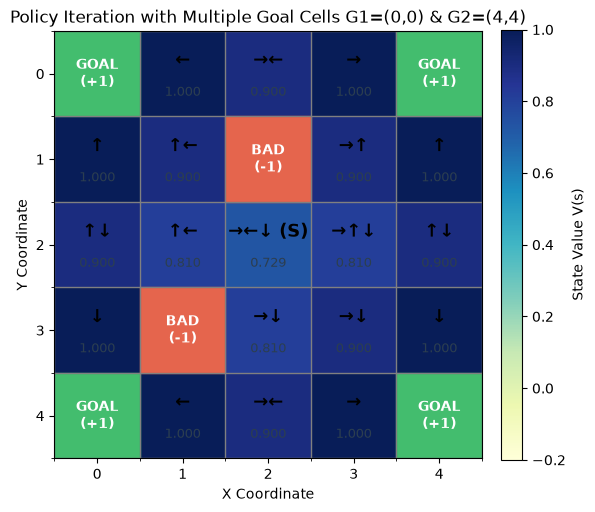

In [18]:
multi_goal_env = GridMazeEnv(render_mode="ansi")
multi_goal_env.reset(seed=0)
multi_goal_env.agent_pos = np.array([2, 2], dtype=np.int32)
multi_goal_env.goal_pos = np.array([0, 0], dtype=np.int32)  # Goal 1
multi_goal_env.extra_goals = [
    np.array([4, 4], dtype=np.int32),
    np.array([4, 0], dtype=np.int32),
    np.array([0, 4], dtype=np.int32),
]  # Goal 2
multi_goal_env.bad1_pos = np.array([2, 1], dtype=np.int32)
multi_goal_env.bad2_pos = np.array([1, 3], dtype=np.int32)

print("Multi-Goal Maze Layout (ANSI):")
multi_goal_env.render()

V_multi, policy_multi, iters_multi, sweeps_multi = policy_iteration(
    multi_goal_env, gamma=0.9
)
print(
    f"\nMulti-Goal Policy Iteration converged in {iters_multi} iterations ({sweeps_multi} evaluation sweeps)."
)
plot_value_and_policy(
    multi_goal_env,
    V_multi,
    policy_multi,
    title="Policy Iteration with Multiple Goal Cells G1=(0,0) & G2=(4,4)",
)

## 7. Synchronous vs. Asynchronous (In-Place) Policy Evaluation Comparison

We compare **Synchronous Policy Evaluation** (two-array approach: $V$ and $V_{\text{new}}$) against **Asynchronous (In-Place / Gauss-Seidel) Policy Evaluation** (single array $V(s)$ updated immediately in-place during each sweep) across 200 random $5 \times 5$ episodes.


In [ ]:
def async_policy_evaluation(env, policy, V, gamma=0.9, theta=1e-6):
    """
    Asynchronous (In-Place / Gauss-Seidel) Policy Evaluation.
    Updates V[x, y] directly in-place so neighboring states immediately use updated values.
    """
    grid_size = env.grid_size
    n_actions = env.action_space.n
    sweeps = 0

    while True:
        delta = 0.0
        sweeps += 1

        for x in range(grid_size):
            for y in range(grid_size):
                state = (x, y)
                if env.is_terminal(state):
                    V[x, y] = 0.0
                    continue

                old_v = V[x, y]
                new_v = 0.0
                for a in range(n_actions):
                    action_prob = policy[x, y, a]
                    if action_prob > 0:
                        next_state, reward, terminated = env.get_transition_model(
                            state, a
                        )
                        nx, ny = next_state
                        next_val = 0.0 if terminated else V[nx, ny]
                        new_v += action_prob * (reward + gamma * next_val)

                V[x, y] = new_v
                delta = max(delta, abs(new_v - old_v))

        if delta < theta:
            break

    return V, sweeps


def async_policy_iteration(env, gamma=0.9, theta=1e-6, tie_tol=1e-8):
    grid_size = env.grid_size
    n_actions = env.action_space.n
    V = np.zeros((grid_size, grid_size), dtype=np.float64)
    policy = np.ones((grid_size, grid_size, n_actions), dtype=np.float64) / n_actions

    num_iterations = 0
    total_sweeps = 0

    while True:
        num_iterations += 1
        V, sweeps = async_policy_evaluation(env, policy, V, gamma=gamma, theta=theta)
        total_sweeps += sweeps
        policy, policy_stable = policy_improvement(
            env, policy, V, gamma=gamma, tie_tol=tie_tol
        )
        if policy_stable:
            break

    return V, policy, num_iterations, total_sweeps


# Benchmark Sync vs Async across 200 identical random maze layouts
comp_env = GridMazeEnv(render_mode=None)
num_trials = 200

sync_iters, sync_sweeps, sync_times = [], [], []
async_iters, async_sweeps, async_times = [], [], []
max_v_diffs = []

for ep in range(num_trials):
    comp_env.reset(seed=500 + ep)

    t0 = time.perf_counter()
    V_sync, pi_sync, it_s, sw_s = policy_iteration(comp_env, gamma=0.9, theta=1e-6)
    sync_times.append((time.perf_counter() - t0) * 1000)
    sync_iters.append(it_s)
    sync_sweeps.append(sw_s)

    t0 = time.perf_counter()
    V_async, pi_async, it_a, sw_a = async_policy_iteration(
        comp_env, gamma=0.9, theta=1e-6
    )
    async_times.append((time.perf_counter() - t0) * 1000)
    async_iters.append(it_a)
    async_sweeps.append(sw_a)

    max_v_diffs.append(np.max(np.abs(V_sync - V_async)))

comp_env.close()

print(f"=== Synchronous vs. Asynchronous Policy Evaluation ({num_trials} Episodes) ===")
print(
    f"{'Metric':<35} | {'Synchronous (2-Array)':<22} | {'Asynchronous (In-Place)':<22}"
)
print("-" * 85)
print(
    f"{'Avg Outer PI Iterations':<35} | {np.mean(sync_iters):<22.2f} | {np.mean(async_iters):<22.2f}"
)
print(
    f"{'Avg Total Evaluation Sweeps':<35} | {np.mean(sync_sweeps):<22.2f} | {np.mean(async_sweeps):<22.2f}"
)
print(
    f"{'Min / Max Evaluation Sweeps':<35} | {f'{np.min(sync_sweeps)} / {np.max(sync_sweeps)}':<22} | {f'{np.min(async_sweeps)} / {np.max(async_sweeps)}':<22}"
)
print(
    f"{'Avg Solve Time per Episode (ms)':<35} | {np.mean(sync_times):<22.2f} | {np.mean(async_times):<22.2f}"
)
print(
    f"\nSweep Reduction with Async: {(1 - np.mean(async_sweeps) / np.mean(sync_sweeps)) * 100:.1f}% fewer sweeps"
)
print(
    f"Max Value Difference |V_sync - V_async|: {np.max(max_v_diffs):.2e} (Identical optimal policies)"
)

=== Synchronous vs. Asynchronous Policy Evaluation (200 Episodes) ===
Metric                              | Synchronous (2-Array)  | Asynchronous (In-Place)
-------------------------------------------------------------------------------------
Avg Outer PI Iterations             | 4.26                   | 4.25                  
Avg Total Evaluation Sweeps         | 141.03                 | 110.25                
Min / Max Evaluation Sweeps         | 51 / 248               | 35 / 210              
Avg Solve Time per Episode (ms)     | 652.16                 | 468.19                

Sweep Reduction with Async: 21.8% fewer sweeps
Max Value Difference |V_sync - V_async|: 4.06e-19 (Identical optimal policies)
